In [1]:
import kagglehub

path = kagglehub.dataset_download("jessicali9530/caltech256")

print("Path to dataset files:", path)

100%|██████████| 2.12G/2.12G [01:41<00:00, 22.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/jessicali9530/caltech256/versions/2


In [2]:
import os, random, numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing import image

In [3]:
DATASET_DIR = os.path.join(path, "256_ObjectCategories")
print(os.path.exists(DATASET_DIR))

exts = {".jpg", ".jpeg", ".png"}
by_class = defaultdict(list)

for cat in sorted(os.listdir(DATASET_DIR)):
    if cat.startswith("257"):
        continue
    cdir = os.path.join(DATASET_DIR, cat)
    if not os.path.isdir(cdir):
        continue
    name = cat.split(".", 1)[1]
    for f in os.listdir(cdir):
        if os.path.splitext(f)[1].lower() in exts:
            by_class[name].append(os.path.join(cdir, f))

MAX_PER_CLASS = 60
random.seed(0)
paths, labels = [], []
held_out = []
for name, ps in by_class.items():
    random.shuffle(ps)
    for p in ps[:MAX_PER_CLASS]:
        paths.append(p); labels.append(name)
    held_out += [(p, name) for p in ps[MAX_PER_CLASS:MAX_PER_CLASS + 2]]

labels = np.array(labels)
print(len(paths), "images |", len(set(labels)), "categories |", len(held_out), "held-out")

True
15360 images | 256 categories | 512 held-out


In [4]:
model = MobileNetV2(weights="imagenet", include_top=False,
                    pooling="avg", input_shape=(224, 224, 3))

def load(p):
    img = image.load_img(p, target_size=(224, 224))
    return preprocess_input(image.img_to_array(img))

def extract(plist, batch=64):
    feats = []
    for i in range(0, len(plist), batch):
        x = np.stack([load(p) for p in plist[i:i+batch]])
        feats.append(model.predict(x, verbose=0))
    f = np.vstack(feats)
    return f / np.linalg.norm(f, axis=1, keepdims=True)

print(tf.config.list_physical_devices("GPU"))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
features = extract(paths)
np.save("features.npy", features)
np.save("labels.npy", labels)
print(features.shape)

(15360, 1280)


In [6]:
def predict_and_search(query_path, k_vote=15, k_show=8):
    q = extract([query_path])[0]
    sims = features @ q

    top = np.argsort(-sims)[:k_vote]
    votes = defaultdict(float)
    for i in top:
        votes[labels[i]] += sims[i]
    best = max(votes, key=votes.get)
    confidence = votes[best] / sum(votes.values())

    in_cat = np.where(labels == best)[0]
    ranked = in_cat[np.argsort(-sims[in_cat])][:k_show]
    return best, confidence, [(paths[i], float(sims[i])) for i in ranked]

def show_result(query_path, cat, conf, results):
    n = len(results) + 1
    plt.figure(figsize=(2.6 * n, 3.6))
    plt.subplot(1, n, 1)
    plt.imshow(image.load_img(query_path))
    plt.title(f"Query\n-> {cat}\n({conf:.0%})", fontsize=9)
    plt.axis("off")
    for j, (p, s) in enumerate(results, start=2):
        plt.subplot(1, n, j)
        plt.imshow(image.load_img(p))
        plt.title(f"{s:.2f}", fontsize=9)
        plt.axis("off")
    plt.show()

Real category: waterfall
Predicted: waterfall (67%)


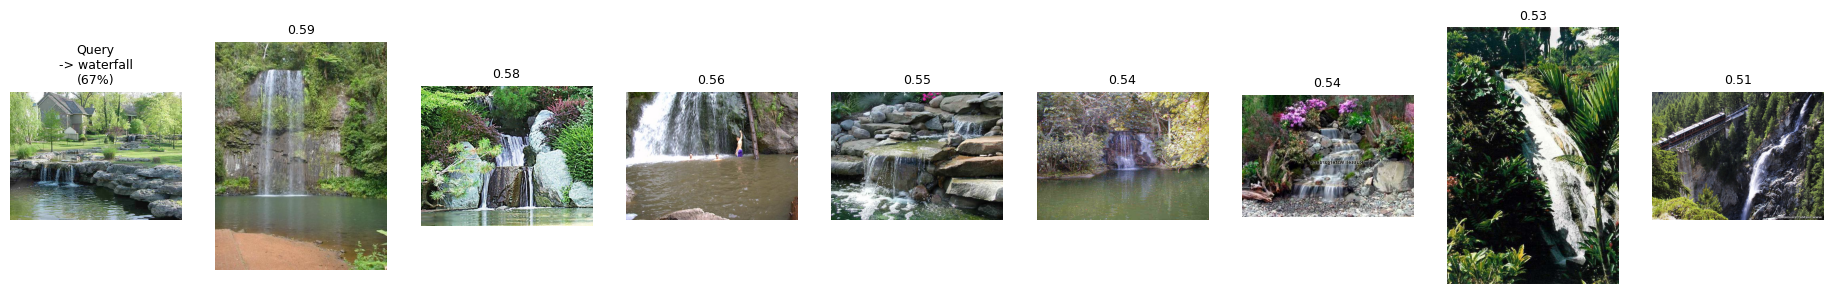

In [7]:
qp, real = random.choice(held_out)
print("Real category:", real)
cat, conf, res = predict_and_search(qp)
print("Predicted:", cat, f"({conf:.0%})")
show_result(qp, cat, conf, res)

In [8]:
def category_accuracy(n=500, k_vote=15):
    correct = 0
    for i in random.sample(range(len(paths)), n):
        sims = features @ features[i]
        sims[i] = -1
        top = np.argsort(-sims)[:k_vote]
        votes = defaultdict(float)
        for j in top:
            votes[labels[j]] += sims[j]
        correct += (max(votes, key=votes.get) == labels[i])
    return correct / n

print("Category accuracy:", category_accuracy())

Category accuracy: 0.786


In [9]:
def heldout_accuracy(k_vote=15):
    hp = [p for p, _ in held_out]
    hl = [l for _, l in held_out]
    hf = extract(hp)
    correct = 0
    for f, real in zip(hf, hl):
        sims = features @ f
        top = np.argsort(-sims)[:k_vote]
        votes = defaultdict(float)
        for j in top:
            votes[labels[j]] += sims[j]
        correct += (max(votes, key=votes.get) == real)
    return correct / len(hl)

print("Held-out accuracy:", heldout_accuracy())

Held-out accuracy: 0.740234375


Saving images (5).jfif to images (5).jfif
Predicted category: waterfall (94%)


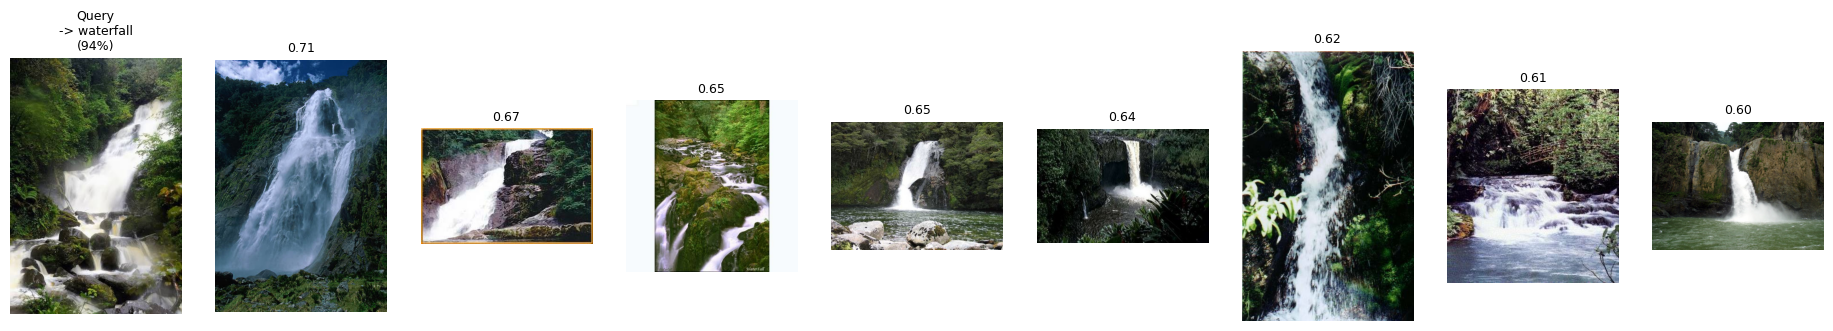

In [10]:
from google.colab import files
up = files.upload()
qpath = list(up.keys())[0]
cat, conf, res = predict_and_search(qpath)
print("Predicted category:", cat, f"({conf:.0%})")
show_result(qpath, cat, conf, res)